In [ ]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../top_50_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2023-06-01"
END = "2025-06-01"
DATASET = "XNAS.ITCH"

df_bars = (
    adapter.scan_data(
        tickers="ALL_SYMBOLS",
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="ohlcv-1d"
    )
    .select(["ts_event", "symbol", "close"])
    .with_columns(
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(
        pl.col("symbol").is_in(ACTIVE_SET)
    )
    .sort(["ts_event", "symbol"])
)

CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 548cfb7cc98703d7d8a8a14fe79dfe1a.parquet


In [2]:
CAX = (
     pl.read_csv("../CAX/corporate_actions.csv")
     .sort(["date", "symbol"])
     .with_columns(
         pl.col("date").str.to_datetime(time_unit="ns", time_zone="UTC"),
         pl.col("symbol").cast(pl.Categorical)
     )
)
CAX

symbol,date,dividend,split
cat,"datetime[ns, UTC]",f64,f64
"""AGG""",2023-06-01 00:00:00 UTC,0.258,0.0
"""AJG""",2023-06-01 00:00:00 UTC,0.55,0.0
"""ALL""",2023-06-01 00:00:00 UTC,0.89,0.0
"""ANGL""",2023-06-01 00:00:00 UTC,0.131,0.0
"""BAC""",2023-06-01 00:00:00 UTC,0.22,0.0
…,…,…,…
"""FIS""",2026-06-11 00:00:00 UTC,0.44,0.0
"""FNV""",2026-06-11 00:00:00 UTC,0.44,0.0
"""JXN""",2026-06-11 00:00:00 UTC,0.9,0.0


In [3]:
daily_px = (
      df_bars
      .collect(engine="streaming")
    #   .filter(pl.col("symbol").is_in(ACTIVE_SET))
      .join(CAX, left_on=["ts_event", "symbol"], right_on=["date", "symbol"], how="left")
      .sort(["symbol", "ts_event"])
      .with_columns(
          pl.col("dividend").fill_null(0.0),
          # 0.0 / null == "no split" -> ratio of 1.0, not 0.0
          pl.when(pl.col("split").fill_null(0.0) == 0.0)
            .then(1.0).otherwise(pl.col("split")).alias("split"),
      )
      .with_columns(
          (pl.col("split") / (1 - pl.col("dividend") / pl.col("close").shift().over("symbol"))).alias("CAX")
      )
      .with_columns(pl.col("CAX").fill_null(1.0))            # first row per symbol: no prev_close
      .with_columns(pl.col("CAX").cum_prod().over("symbol"))
  )
daily_px

ts_event,symbol,close,dividend,split,CAX
"datetime[ns, UTC]",cat,f64,f64,f64,f64
2023-06-01 00:00:00 UTC,"""AAPL""",180.58,0.0,1.0,1.0
2023-06-02 00:00:00 UTC,"""AAPL""",181.1,0.0,1.0,1.0
2023-06-05 00:00:00 UTC,"""AAPL""",179.12,0.0,1.0,1.0
2023-06-06 00:00:00 UTC,"""AAPL""",179.04,0.0,1.0,1.0
2023-06-07 00:00:00 UTC,"""AAPL""",177.9,0.0,1.0,1.0
…,…,…,…,…,…
2025-05-23 00:00:00 UTC,"""VRTX""",436.0,0.0,1.0,1.0
2025-05-27 00:00:00 UTC,"""VRTX""",445.01,0.0,1.0,1.0
2025-05-28 00:00:00 UTC,"""VRTX""",445.36,0.0,1.0,1.0


In [4]:
adj_px = (
    daily_px
    .with_columns((pl.col("close") * pl.col("CAX")).alias("adj_close"))
    .select(["ts_event", "symbol", "adj_close"])
)
adj_px

ts_event,symbol,adj_close
"datetime[ns, UTC]",cat,f64
2023-06-01 00:00:00 UTC,"""AAPL""",180.58
2023-06-02 00:00:00 UTC,"""AAPL""",181.1
2023-06-05 00:00:00 UTC,"""AAPL""",179.12
2023-06-06 00:00:00 UTC,"""AAPL""",179.04
2023-06-07 00:00:00 UTC,"""AAPL""",177.9
…,…,…
2025-05-23 00:00:00 UTC,"""VRTX""",436.0
2025-05-27 00:00:00 UTC,"""VRTX""",445.01
2025-05-28 00:00:00 UTC,"""VRTX""",445.36


In [5]:
daily_ret = (
    adj_px
    .with_columns(
        pl.col("adj_close").pct_change().over("symbol").alias("ret")
    )
    .pivot(
        on="symbol",
        on_columns=ACTIVE_SET,
        index="ts_event",
        values="ret"
    )
    .with_columns(
        pl.all().exclude("ts_event").fill_null(pl.all().exclude("ts_event").mean())
    )
    .with_columns(
        (pl.all().exclude("ts_event") - pl.all().exclude("ts_event").mean()).round(6)
    )
)
daily_ret

ts_event,NVDA,TSLA,AAPL,MSFT,AMZN,META,GOOGL,AVGO,PLTR,MSTR,GOOG,NFLX,AMD,COST,COIN,APP,MU,SMCI,QCOM,TXN,CRWD,CSCO,INTC,HOOD,ADBE,BKNG,MRVL,AMAT,TMUS,PEP,INTU,ISRG,LRCX,CRWV,DASH,GILD,AMGN,ADI,KLAC,PANW,SBUX,CMCSA,CEG,HON,VRTX,MELI,NXPI,PYPL,ABNB,REGN
"datetime[ns, UTC]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2023-06-01 00:00:00 UTC,-0.0,-0.0,0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0,-0.0,0.0,0.0
2023-06-02 00:00:00 UTC,-0.021408,0.026902,0.00249,0.004946,0.006565,-0.004621,0.007726,0.043334,-0.008817,-0.000188,0.007765,-0.011219,-0.020249,0.00627,0.014123,0.004703,0.001497,-0.042313,-0.003653,-0.003304,-0.044435,0.003118,0.008344,0.023769,0.023035,0.024091,-0.0215,0.000356,-0.063681,0.008266,0.01907,0.006028,-0.013176,0.0,-0.001252,0.022483,0.01534,-0.001203,0.013299,0.058002,0.01893,0.002037,-0.014861,0.025044,0.027102,0.006266,0.009687,0.010431,0.035546,0.014157
2023-06-05 00:00:00 UTC,-0.009008,0.008421,-0.011323,0.000288,0.006263,-0.008301,0.00974,-0.014004,0.054365,-0.086325,0.010169,0.003448,0.001576,0.008982,-0.098401,0.034828,-0.023388,-0.004415,-0.027608,-0.032469,0.012681,0.002703,-0.053782,-0.033898,-0.006,0.019152,-0.040247,-0.014688,0.008408,0.00494,0.024533,0.014036,-0.014585,0.0,0.018176,-0.003326,0.015954,-0.034235,-0.005362,-0.011906,0.004105,0.017107,-0.014087,-0.004164,-0.005456,0.010916,-0.036455,0.00906,-0.012395,0.014138
2023-06-06 00:00:00 UTC,-0.008403,0.03989,-0.000836,-0.007403,0.010126,0.00153,0.009549,-0.021866,0.00906,0.072786,0.009495,-0.009208,0.059541,-0.003343,-0.09896,-0.10432,0.000812,0.058019,0.031883,0.001779,-0.00234,-0.00807,0.041037,0.002806,-0.002603,0.011442,0.029326,0.00315,-0.023548,-0.015178,0.010354,-0.006676,0.008665,0.0,0.028424,-0.020688,-0.003838,0.023553,0.003315,-0.011663,-0.01663,-0.008803,0.036381,-0.004178,-0.003788,-0.025783,0.030678,0.00835,0.023964,-0.001843
2023-06-07 00:00:00 UTC,-0.029175,-0.010576,-0.006757,-0.032833,-0.041243,-0.034214,-0.037731,0.003366,-0.065435,-0.040639,-0.039038,-0.002475,-0.054513,-0.012039,0.001993,-0.083974,-0.006868,0.011281,-0.010701,0.012303,-0.031776,-0.001098,0.009376,0.015905,-0.034265,-0.028892,-0.002328,0.009274,-0.014644,-0.008878,-0.056721,-0.027957,-0.000493,0.0,-0.023557,-0.004295,0.002753,0.010438,0.004532,-0.040029,-0.003374,0.025838,0.001102,0.005302,-0.017537,-0.035526,0.026533,-0.017699,-0.017193,-0.013211
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2025-05-23 00:00:00 UTC,-0.015441,-0.008513,-0.028189,-0.008497,-0.013214,-0.019099,-0.021767,-0.014884,-0.002438,-0.097906,-0.022134,-0.006077,-0.006863,-0.01245,-0.047098,-0.000818,-0.021052,-0.037392,-0.016746,-0.025554,0.022936,-0.005596,-0.024931,-0.034908,-0.014713,-0.003628,-0.019242,-0.017609,0.005508,-0.003983,-0.000757,-0.002517,-0.02091,-0.013871,0.0203,-0.004209,-0.003321,-0.009108,-0.017646,-0.002024,0.00332,-0.001748,-0.036145,-0.006841,0.008675,-0.012877,-0.019116,-0.023307,-0.008258,-0.013034
2025-05-27 00:00:00 UTC,0.030599,0.079291,0.022946,0.021594,0.026721,0.023434,0.027281,0.033191,-0.007782,0.007697,0.027433,0.020325,0.040929,0.009064,0.013757,0.070302,0.036335,0.054583,0.02607,0.04279,0.033813,0.012646,0.024738,0.050193,0.012888,0.018969,0.058837,0.027462,0.004926,0.015082,0.040965,0.01917,0.03864,0.150917,-0.011214,0.028744,0.030805,0.032379,0.044188,0.003184,0.033464,0.01826,0.03641,0.020055,0.019894,0.017488,0.034803,0.023725,0.022974,0.022866
2025-05-28 00:00:00 UTC,0.039684,-0.009658,0.034838,0.001668,0.02766,0.016473,0.011467,0.045791,0.015875,-0.010434,0.009882,-0.005769,0.005272,-0.002006,-0.030802,0.046352,0.028762,0.02299,0.009259,0.01507,0.000065,-0.006182,0.002269,-0.000852,0.004948,0

In [6]:
# causal_vol = daily_ret.with_columns(pl.all().exclude("ts_event").pow(2).ewm_mean(alpha=0.06, adjust=True).sqrt().shift(1))
# st_ret = daily_ret.select(pl.all().exclude("ts_event")) / causal_vol.select(pl.all().exclude("ts_event"))
# st_ret


# floor the vol so a collapsed forecast can't produce a divide-by-~0
# (cross-sectional: e.g. 1st percentile of that day's vols, or a small abs floor)
causal_vol = daily_ret.with_columns(
    pl.all().exclude("ts_event").pow(2).ewm_mean(alpha=0.06, adjust=True).sqrt().shift(1)
)
CAUSAL_VOL_FLOOR = 1e-3   # ~0.1%/day
st_ret = (
    daily_ret.select(pl.all().exclude("ts_event"))
    / causal_vol.select(pl.all().exclude("ts_event")).select(pl.all().clip(lower_bound=CAUSAL_VOL_FLOOR))
).select(pl.all().clip(-10, 10))   # a >10σ standardized daily return is a data artifact

st_ret


NVDA,TSLA,AAPL,MSFT,AMZN,META,GOOGL,AVGO,PLTR,MSTR,GOOG,NFLX,AMD,COST,COIN,APP,MU,SMCI,QCOM,TXN,CRWD,CSCO,INTC,HOOD,ADBE,BKNG,MRVL,AMAT,TMUS,PEP,INTU,ISRG,LRCX,CRWV,DASH,GILD,AMGN,ADI,KLAC,PANW,SBUX,CMCSA,CEG,HON,VRTX,MELI,NXPI,PYPL,ABNB,REGN
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
-10.0,10.0,2.49,4.946,6.565,-4.621,7.726,10.0,-8.817,-0.188,7.765,-10.0,-10.0,6.27,10.0,4.703,1.497,-10.0,-3.653,-3.304,-10.0,3.118,8.344,10.0,10.0,10.0,-10.0,0.356,-10.0,8.266,10.0,6.028,-10.0,0.0,-1.252,10.0,10.0,-1.203,10.0,10.0,10.0,2.037,-10.0,10.0,10.0,6.266,9.687,10.0,10.0,10.0
-0.586075,0.435993,-6.333781,0.081103,1.328766,-2.502046,1.755922,-0.450116,8.588146,-10.0,1.824054,0.428069,0.108406,1.995292,-9.704506,10.0,-10.0,-0.145331,-10.0,-10.0,0.397493,1.207455,-8.977668,-1.986388,-0.362797,1.107287,-2.60733,-10.0,0.183901,0.832401,1.791847,3.243179,-1.541785,0.0,10.0,-0.206048,1.448589,-10.0,-0.561576,-0.285906,0.302039,10.0,-1.320296,-0.231584,-0.280397,2.426465,-5.241658,1.209771,-0.485687,1.39097
-0.624055,2.445601,-0.121337,-2.589461,1.905485,0.272552,1.305882,-0.829662,0.276635,1.416811,1.261014,-1.355991,5.079902,-0.517938,-1.673776,-4.99057,0.058228,2.362836,1.924781,0.091623,-0.087556,-3.343956,1.267891,0.115031,-0.189143,0.636535,1.087223,0.360271,-0.635026,-2.709093,0.566356,-0.73783,0.750977,0.0,2.621936,-1.576538,-0.295684,1.155382,0.398901,-0.340944,-1.485865,-0.858981,3.033827,-0.284976,-0.237181,-3.468014,1.369358,1.033364,1.099489,-0.157165
-2.374099,-0.421797,-1.147544,-7.175981,-5.917776,-7.053381,-4.724116,0.133538,-2.311245,-0.700386,-4.810636,-0.328699,-1.666557,-2.085711,0.027588,-1.462794,-0.577506,0.305997,-0.489721,0.742308,-1.393067,-0.233817,0.268242,0.763154,-2.901946,-1.756619,-0.084235,1.215202,-0.431731,-0.958217,-3.438597,-3.302533,-0.04553,0.0,-1.345657,-0.27598,0.244862,0.490066,0.621524,-1.343908,-0.261349,2.616838,0.051013,0.417989,-1.274973,-2.384002,1.063787,-2.170307,-0.767207,-1.315782
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
-0.400951,-0.185018,-0.997228,-0.414814,-0.435369,-0.544211,-0.777881,-0.401753,-0.047433,-2.020114,-0.787855,-0.267392,-0.173723,-0.861658,-0.828469,-0.014069,-0.481423,-0.499992,-0.579086,-0.799101,0.667921,-0.309043,-0.69326,-0.56203,-0.770736,-0.15557,-0.410263,-0.525021,0.27871,-0.296493,-0.026589,-0.098666,-0.577629,-0.14067,0.609632,-0.167485,-0.160678,-0.257619,-0.538185,-0.073316,0.118819,-0.096792,-0.829399,-0.345006,0.361205,-0.471117,-0.497602,-1.019306,-0.268357,-0.41622
0.815346,1.775482,0.811884,1.081397,0.902611,0.682295,0.986693,0.919328,-0.15615,0.1459,0.987776,0.920316,1.067559,0.632218,0.2443,1.247109,0.850758,0.746862,0.920047,1.352838,1.001452,0.718142,0.698869,0.825237,0.683509,0.83831,1.286999,0.837187,0.256457,1.154739,1.484057,0.774835,1.089412,1.57759,-0.343303,1.178671,1.535986,0.942619,1.377361,0.118938,1.234715,1.042575,0.843413,1.039257,0.850827,0.655293,0.927113,1.036375,0.768271,0.749002
1.068223,-0.203519,1.245452,0.08311,0.939567,0.487502,0.415065,1.274257,0.328294,-0.203857,0.356079,-0.262428,0.136938,-0.142509,-0.563104,0.808888,0.679092,0.318831,0.328278,0.465009,0.001925,-0.356278,0.065108,-0.014144,0.266713,0.460558,1.133991,0.53976,-0.237116,-0.056099,0.413725,0.168928,0.611042,-0.223768,0.714843,-0.345198,0.03452,0.216884,0.20353,0.465449,0.116291,-0.033087,0.361566,-0.214488,0.000647,0.218863,0.082904,0.582354,0.23414,-0.27606


In [7]:
null_columns = [
    col for col in st_ret.columns 
    if st_ret.select(pl.col(col).is_null().all()).item()
]
null_columns

[]

In [8]:
sym_cols = [c for c in daily_ret.columns if c != "ts_event"]

X = (
    st_ret
    .select(sym_cols)
    .slice(1)                                              # (a) drop warm-up row from shift(1)
    .with_columns(pl.all().exclude("ts_event").fill_null(0.0))  # (c) zero = mean of a demeaned series
    .to_numpy()
)

R=(
    daily_ret
    .select(sym_cols)
    .slice(1)
    .to_numpy()
)
name_vol = R.std(axis=0, ddof=1)                        # (p,)  sigma[i]  in return units
name_vol = np.maximum(name_vol, CAUSAL_VOL_FLOOR)       # floor

lo, hi = np.percentile(name_vol, [2.5, 97.5])
name_vol = np.clip(name_vol, lo, hi)

In [9]:
# Best rank k approximation of the returns covariance matrix
U, s, Vt = np.linalg.svd(X)
k = 10
U_k, S_k, Vt_k = U[:, :k], np.diag(s[:k]), Vt[:k, :]
F = U_k
L = S_k @ Vt_k

# Residuals: what the market factor can't explain
# Adding a floor to epsilon volatility for illiquid names
eps = X - F @ L          # (T, p)
eps_var  = np.var(eps, axis=0)
EPS_FLOOR = 0.1
eps_var  = np.maximum(eps_var, EPS_FLOOR)
D = np.diag(eps_var)         # (2000, 2000) diagonal

# Factor covariance
Sigma_f = np.cov(F, rowvar=False)       # (10, 10)

# Model-implied return covariance: Σ_r = L^T Σ_f L + D
Sigma_r = L.T @ Sigma_f @ L + D         # (2000, 2000)


In [10]:
S = np.diag(name_vol)
L_ret   = L @ S                      # (k, p)  return-unit loadings  B
Dz_diag = eps_var                    # standardized idio var (what you already floor)
Dr_diag = name_vol**2 * Dz_diag      # return-unit idio var  (fallback until GARCH)
Sigma_r_ret = L_ret.T @ Sigma_f @ L_ret + np.diag(Dr_diag)

np.save("name_vol.npy",              name_vol)
np.save("loadings_return.npy",       L_ret)
np.save("idiosyncratic_diag_return.npy", Dr_diag)
np.save("cov_matrix_return.npy",     Sigma_r_ret)

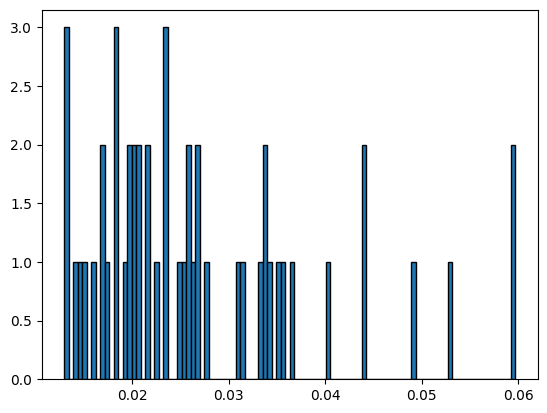

In [11]:
plt.hist(name_vol, bins=100, edgecolor="black")
plt.show()

In [12]:
d = np.diag(Sigma_r_ret)
print("diag  min/median/max:", d.min(), np.median(d), d.max())   # want median ≈ 1, max single digits
print("cond:", np.linalg.cond(Sigma_r_ret))                          # want O(1e1–1e3)

diag  min/median/max: 0.00021132789218811102 0.0007819390514736796 0.005159960013967061
cond: 452.5830863103374


In [13]:
Sigma_r - (L.T @ Sigma_f @ L + D)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(50, 50))

In [14]:
np.save("loadings.npy", L)
np.save("factor_returns.npy", F)
np.save("idiosyncratic_diag_vec.npy", eps_var)
np.save("factor_cov_matrix.npy", Sigma_f)
np.save("cov_matrix.npy", Sigma_r)
